# Vaje 02

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from scipy.integrate import solve_ivp
from scipy.special import ellipk

L = 1.0
g = 9.81
T0_lin =2*np.pi*np.sqrt(L/g)
print(T0_lin)

2.0060666807106475


# Naloga 1

In [5]:
th0 = sp.symbols("theta_0", positive=True)
T_rel_sym = 4 /sp.pi * sp.elliptic_k(sp.sin(th0 / 2)**2)
T_rel_series = sp.series(T_rel_sym, th0, 0, 6).removeO()

In [6]:
display(T_rel_sym)
display(T_rel_series)

4*elliptic_k(sin(theta_0/2)**2)/pi

11*theta_0**4/1536 + theta_0**2/8 + 2

In [14]:
# k pri 60° je
k = np.sin(0.5*60*np.pi/180)**2
print(f"k = {k}")
for n in range(6,7):
    T_rel_series = sp.series(T_rel_sym, th0, 0, n).removeO()
    for theta in range(0,91,10):
        T0_aprox = T_rel_series.subs(th0, theta*np.pi/180)
        print(f"theta = {theta}, rel(delta_T0) = {((T0_aprox-T0_lin)/T0_lin*100):.2f} %, {T0_aprox:.3f}")

k = 0.24999999999999994
theta = 0, rel(delta_T0) = -0.30 %, 2.000
theta = 10, rel(delta_T0) = -0.11 %, 2.004
theta = 20, rel(delta_T0) = 0.46 %, 2.015
theta = 30, rel(delta_T0) = 1.43 %, 2.035
theta = 40, rel(delta_T0) = 2.82 %, 2.063
theta = 50, rel(delta_T0) = 4.65 %, 2.099
theta = 60, rel(delta_T0) = 6.96 %, 2.146
theta = 70, rel(delta_T0) = 9.79 %, 2.203
theta = 80, rel(delta_T0) = 13.20 %, 2.271
theta = 90, rel(delta_T0) = 17.25 %, 2.352


# Naloga 2

In [15]:
theta0_deg = [10, 30, 60, 90, 120, 150]
rtol = 1e-10
atol = 1e-12

def rhs_nihalo(t, y):
    theta, omega_v = y
    return [omega_v, -g / L * np.sin(theta)]

def prehod(t, y, *args):
    # pozitiven prehod skozi 0
    return y[0]

def perioda(rhs, y0, t_end, args=()):
    # T = razmik med zaporednima pozitivnima prehodoma
    sol = solve_ivp(rhs, (0, t_end), y0, args=args,
                    events = prehod, rtol=rtol,
                    atol=atol, dense_output=True)
    t_ev = sol.t_events[0]
    return np.mean(np.diff(t_ev)*2), sol

t_end = 10.0
t_plot = np.linspace(0, t_end, 2_000)

rez_nihalo = {}  # theta0_deg -> (T_num, sol)

for deg in theta0_deg:
    rez_nihalo[deg] = perioda(rhs_nihalo, [np.radians(deg), 0.0], t_end)
    print(f" Theta = {deg:.0f}, <T> = {rez_nihalo[deg][0]:.3f}")

 Theta = 10, <T> = 2.010
 Theta = 30, <T> = 2.041
 Theta = 60, <T> = 2.153
 Theta = 90, <T> = 2.368
 Theta = 120, <T> = 2.754
 Theta = 150, <T> = 3.535


In [26]:
rez_nihalo[10][1].y

array([[ 0.17453293,  0.17453094,  0.17448389, ...,  0.17105955,
         0.17203936,  0.17245315],
       [ 0.        , -0.00260119, -0.01292429, ...,  0.10824567,
         0.0918446 ,  0.08392831]], shape=(2, 959))

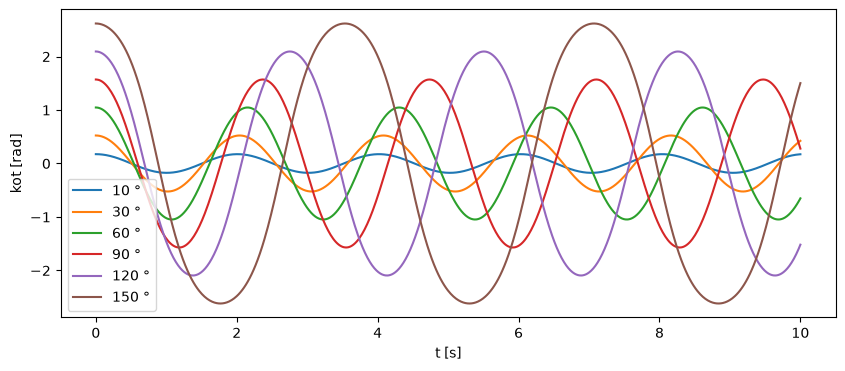

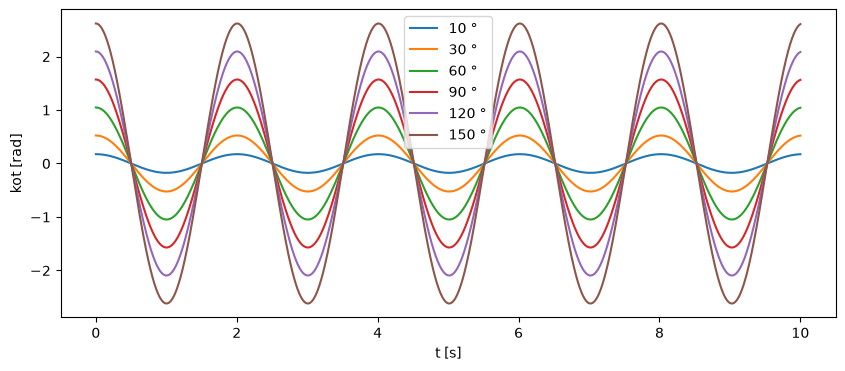

In [29]:
plt.figure(figsize=(10,4))
for kot in rez_nihalo:
    x = rez_nihalo[kot][1].t
    y = rez_nihalo[kot][1].y[0]
    plt.plot(x,y, label = f"{kot:.0f} °")
plt.xlabel("t [s]")
plt.ylabel("kot [rad]")
plt.legend()
plt.show()
plt.close()


plt.figure(figsize=(10,4))
for kot in rez_nihalo:
    x = t_plot#rez_nihalo[kot][1].t
    y = kot*np.pi/180*np.cos(2*np.pi/T0_lin*x)#rez_nihalo[kot][1].y[0]
    plt.plot(x,y, label = f"{kot:.0f} °")
plt.xlabel("t [s]")
plt.ylabel("kot [rad]")
plt.legend()
plt.show()
plt.close()

# Naloga 3

In [31]:
def rhs_duffing(t, y, alpha):
    x, v = y
    return [v, -omega0**2 * x - alpha * x**3]

In [35]:
rez_duffing = {}  # alpha -> omega_num(A)
alpha_list = [-0.1,0.5]
A_list = [0.001,0.2, 1.8]
omega0 = 1.0

for alpha in alpha_list:
    omega_num = []
    for A0 in A_list:
        T_num, _ = perioda(rhs_duffing, [A0, 0.0], 40.0, args=(alpha,))
        omega_num.append(2 * np.pi / T_num)
    rez_duffing[alpha] = np.array(omega_num)
rez_duffing

{-0.1: array([0.99999996, 0.99849868, 0.86818195]),
 0.5: array([1.00000019, 1.0074675 , 1.47884398])}

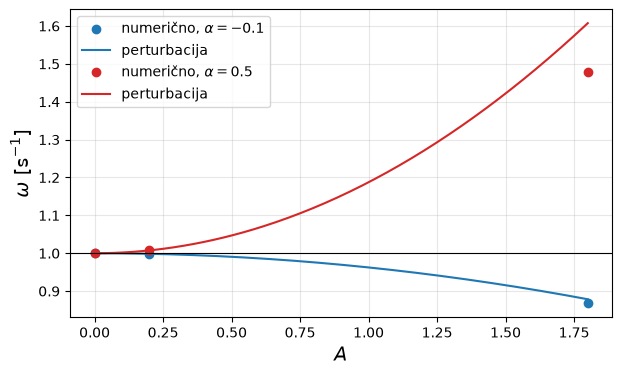

In [38]:
# Simbolno: harmonsko ravnovesje za Duffing, x = A cos(w t)
t, w, w0, A = sp.symbols("t omega omega_0 A", positive=True)
al = sp.symbols("alpha", real=True)
x_ans = A * sp.cos(w * t)
residual = sp.diff(x_ans, t, 2) + w0**2 * x_ans + al * x_ans**3

# projekcija na cos(w t) mora biti 0
c1 = sp.simplify(sp.integrate(residual * sp.cos(w * t), (t, 0, 2 * sp.pi / w)) * w / sp.pi)
w_hb = sp.solve(c1, w)[0]                                  # harmonsko ravnovesje
w_pert = sp.series(w_hb, A, 0, 3).removeO()                # 1. red perturbacije
omega_pert = sp.lambdify((A, al, w0), w_pert, "numpy")

_fine = np.linspace(0, 1.8, 200)
fig = plt.figure(figsize=(7, 4))
ax = fig.add_subplot(111)
for alpha, c in zip(alpha_list, ["C0", "C3"]):
    ax.plot(A_list, rez_duffing[alpha], "o", color=c, label=rf"numerično, $\alpha = {alpha}$")
    ax.plot(A_fine, omega_pert(A_fine, alpha, omega0), "-", color=c, label="perturbacija")
ax.axhline(omega0, color="black", linewidth=0.8)
ax.set_xlabel("$A$", fontsize=14)
ax.set_ylabel(r"$\omega$ [s$^{-1}$]", fontsize=14)
ax.legend()
ax.grid(alpha=0.3)
plt.show()

In [41]:
def foo(x):
    return x, x*x, x*x*x, x+1

_, res, _, _ = foo(1)

In [42]:
res

1